# 03 — Gradient Boosting

Quy ước **human=0, bot=1**, chỉ dùng bốn cột `FEATURE_COLUMNS`. Mọi pipeline chỉ fit trên **train**; cấu hình được chọn theo **AP validation**, sau đó chọn ngưỡng tối đa **F1 bot validation**.

Notebook gọi cùng quy trình với `python -m src.supervised`. Các tệp đầu ra được ghi đè khi chạy lại; `run_id`, hash nguồn, split và mã nguồn liên kết kết quả với từng lần chạy. **Không dự đoán hoặc đánh giá test trong notebook này.** Notebook 04 giữ lịch sử test đã dùng và báo cáo AUC 0,863 của model tạm; không xem test là tập chắc chắn chưa từng quan sát.

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if not (project_root / "src").is_dir():
    raise RuntimeError("Mở notebook từ thư mục gốc dự án hoặc notebooks/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

from src.config import FEATURE_COLUMNS, FIGURES_DIR, MODELS_DIR, REPORTS_DIR
from src.data import load_profiles, split_features
from src.features import build_features
from src.supervised import GRADIENT_BOOSTING_CANDIDATES, run_supervised
from src.train import bot_probabilities

print("Project root:", project_root)

Project root: D:\Project\Social-Media-Bot-Fake-Account-Detection


## Quy tắc cố định trước tìm kiếm

Lưới nhỏ gồm 100/200 cây × độ sâu 2/3/4, learning rate 0,1, tối thiểu 5 mẫu/lá, subsample=1 và seed=42. AP đánh giá thứ hạng lớp bot mà không phụ thuộc ngưỡng. Nếu AP bằng nhau, giữ cấu hình xuất hiện trước trong lưới. Sau khi chọn cấu hình, chọn ngưỡng có F1 bot cao nhất; nếu bằng nhau, lấy ngưỡng nhỏ nhất.

Median imputer nằm trong pipeline và chỉ fit trên train. Mô hình cây không cần scaler hoặc log1p; cột hoàn toàn thiếu được giữ lại, điền 0 theo `keep_empty_features=True`. Không refit trên train+validation sau chọn ngưỡng vì việc đó sẽ đổi score mà ngưỡng đã dựa vào.

In [2]:
display(pd.DataFrame(GRADIENT_BOOSTING_CANDIDATES))
run = run_supervised()
search, results, manifest = run["search"], run["results"], run["manifest"]
print("Run:", manifest["run_id"])
print("Train / validation:", manifest["provenance"]["train_rows"], "/", manifest["provenance"]["validation_rows"])
display(search.sort_values("ap", ascending=False, kind="stable").round(6))

,n_estimators,max_depth,learning_rate,min_samples_leaf,subsample
0,100,2,0.1,5,1.0
1,100,3,0.1,5,1.0
2,100,4,0.1,5,1.0
3,200,2,0.1,5,1.0
4,200,3,0.1,5,1.0
5,200,4,0.1,5,1.0


Run: 20261112T082406Z-d5a53717
Train / validation: 22462 / 7488


,run_id,split,candidate_id,n_estimators,max_depth,learning_rate,min_samples_leaf,subsample,ap,roc_auc,f1_bot_default,fit_seconds,selected
5,20261112T082406Z-d5a53717,validation,5,200,4,0.1,5,1.0,0.787593,0.861547,0.695266,4.339957,True
2,20261112T082406Z-d5a53717,validation,2,100,4,0.1,5,1.0,0.778691,0.857578,0.678187,2.148709,False
4,20261112T082406Z-d5a53717,validation,4,200,3,0.1,5,1.0,0.777855,0.857425,0.681098,3.314831,False
1,20261112T082406Z-d5a53717,validation,1,100,3,0.1,5,1.0,0.764567,0.849858,0.664093,1.675990,False
3,20261112T082406Z-d5a53717,validation,3,200,2,0.1,5,1.0,0.750334,0.844241,0.655558,2.281018,False
0,20261112T082406Z-d5a53717,validation,0,100,2,0.1,5,1.0,0.730323,0.834028,0.618508,1.265357,False


## Kết quả trên validation

Báo cáo tách riêng ngưỡng mặc định 0,5 và ngưỡng F1 chọn trên validation. Các số này dùng để phát triển mô hình, có thể lạc quan vì cùng validation được dùng để chọn cấu hình/ngưỡng. Chưa phải kết quả đánh giá cuối trên test. Thời gian fit là của model được giữ lại; tổng thời gian tìm kiếm nằm trong manifest.

In [3]:
columns = ["model", "threshold_policy", "threshold", "precision_bot", "recall_bot",
           "f1_bot", "macro_f1", "ap", "roc_auc", "accuracy", "fit_seconds", "score_seconds"]
display(results[columns].round(6))
chosen = results[(results["model"] == "gradient_boosting") & (results["threshold_policy"] == "validation_f1")].iloc[0]
config = manifest["models"]["gradient_boosting"]["config"]
display(Markdown(
    f"Cấu hình chọn: **{config['n_estimators']} cây, max_depth={config['max_depth']}**; "
    f"ngưỡng **{chosen['threshold']:.6f}**. "
    f"Validation: F1 bot **{chosen['f1_bot']:.4f}**, AP **{chosen['ap']:.4f}**, "
    f"ROC-AUC **{chosen['roc_auc']:.4f}**. Đây là kết quả của lần chạy `{manifest['run_id']}`, "
    "không dùng để xác nhận con số 0,863 trong ghi chú cũ."
))

,model,threshold_policy,threshold,precision_bot,recall_bot,f1_bot,macro_f1,ap,roc_auc,accuracy,fit_seconds,score_seconds
0,gradient_boosting,default,0.500000,0.776564,0.629376,0.695266,0.782204,0.787593,0.861547,0.816907,4.339957,0.013648
1,gradient_boosting,validation_f1,0.369156,0.685081,0.733602,0.708511,0.777959,0.787593,0.861547,0.799679,4.339957,0.013648


Cấu hình chọn: **200 cây, max_depth=4**; ngưỡng **0.369156**. Validation: F1 bot **0.7085**, AP **0.7876**, ROC-AUC **0.8615**. Đây là kết quả của lần chạy `20261112T082406Z-d5a53717`, không dùng để xác nhận con số 0,863 trong ghi chú cũ.

## Kiểm tra bàn giao và lưu/tải

`models/gradient_boosting.joblib` chứa `model`, `config`, `feature_columns`, `thresholds`, `threshold`, seed, thời gian fit, phiên bản thư viện và provenance. `bot_probabilities()` tìm cột bằng `classes_ == 1`. Quy tắc dự đoán sau hiệu chỉnh là **score >= threshold**.

Đoạn dưới đọc lại model từ đĩa, dùng split đã lưu và đối chiếu từng xác suất với tệp dự đoán validation. Không fit lại tiền xử lý khi tải model.

In [4]:
profiles, _ = load_profiles()
_, validation, _ = split_features(build_features(profiles))
X_val, y_val = validation[list(FEATURE_COLUMNS)], validation["label"].to_numpy()
predictions = pd.read_csv(REPORTS_DIR / "supervised_validation_predictions.csv", dtype={"user_id": "string"})
bundles, scores, labels = {}, {}, {}
for name in ("gradient_boosting",):
    bundle = joblib.load(MODELS_DIR / f"{name}.joblib")
    assert bundle["feature_columns"] == list(FEATURE_COLUMNS)
    assert bundle["run_id"] == manifest["run_id"]
    bundles[name] = bundle
    scores[name] = bot_probabilities(bundle["model"], X_val)
    labels[name] = (scores[name] >= bundle["threshold"]).astype(int)
    saved = predictions.loc[predictions["model"] == name]
    assert saved["user_id"].tolist() == validation["user_id"].tolist()
    np.testing.assert_allclose(scores[name], saved["bot_score"], rtol=1e-14, atol=1e-15)
    np.testing.assert_array_equal(labels[name], saved["prediction_selected"])
    print(name, "— tải lại OK; classes_ =", bundle["model"].classes_, "; threshold =", bundle["threshold"])

gradient_boosting — tải lại OK; classes_ = [0 1] ; threshold = 0.36915560905621475


## Precision–Recall và confusion matrix trên validation

Ma trận dùng ngưỡng đã lưu trong bundle, thứ tự lớp human/bot. Đường Precision–Recall dùng xác suất bot, không dùng nhãn dự đoán để tính AP.

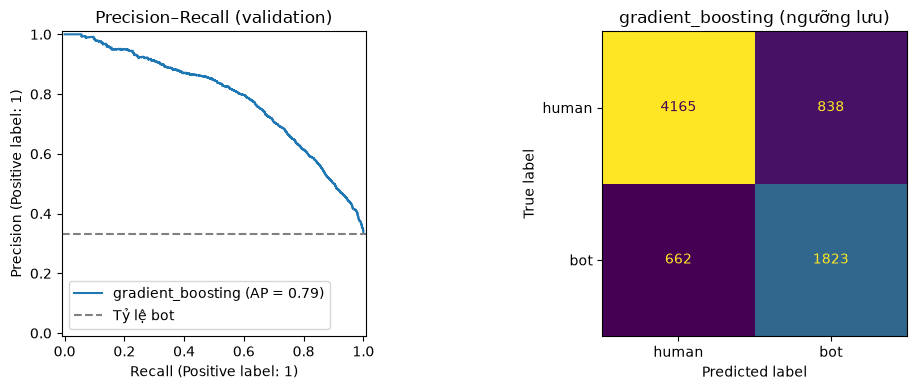

Đã lưu: reports\figures\supervised_validation_diagnostics.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in bundles:
    PrecisionRecallDisplay.from_predictions(y_val, scores[name], name=name, ax=axes[0])
axes[0].axhline(y_val.mean(), color="gray", linestyle="--", label="Tỷ lệ bot")
axes[0].set_title("Precision–Recall (validation)")
axes[0].legend()
for ax, name in zip(axes[1:], bundles):
    ConfusionMatrixDisplay.from_predictions(y_val, labels[name], labels=[0, 1],
                                           display_labels=["human", "bot"], ax=ax, colorbar=False)
    ax.set_title(f"{name} (ngưỡng lưu)")
fig.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
figure_path = FIGURES_DIR / "supervised_validation_diagnostics.png"
fig.savefig(figure_path, dpi=150)
plt.show()
print("Đã lưu:", figure_path.relative_to(project_root))

## Bàn giao cho notebook 04

- Tái tạo: chạy `python -m src.supervised` ở thư mục gốc hoặc Run All notebook này; giữ nguyên `dataset/processed/split.csv`.
- Bảng: `reports/supervised_validation_metrics.csv`; toàn bộ lưới: `reports/supervised_validation_search.csv`; dự đoán theo ID: `reports/supervised_validation_predictions.csv`.
- Cấu hình/ngưỡng và dấu vết lần chạy: `reports/supervised_run.json`. Model sinh ra trong `models/` được Git bỏ qua.
- Gradient Boosting dùng ngưỡng `bundle["thresholds"]["validation_f1"]` và score `bot_probabilities(bundle["model"], X)`.
- Các bộ model này đã khóa cấu hình/ngưỡng cho lần chạy đã ghi. Notebook 04 cần kiểm tra cùng split/hash, đối chiếu lịch sử sử dụng test rồi mới đánh giá cuối; không dùng test để chọn lại mô hình.
- Hàm `evaluate_predictions()` có hợp đồng chung và kiểm thử; AP/ROC-AUC là None khi truth chỉ có một lớp, Macro-F1 luôn tính hai nhãn 0/1. Notebook 04 dùng cùng hợp đồng để so sánh ba mô hình theo đề bài: Isolation Forest, One-Class SVM và Gradient Boosting.